# Apakah Kawasan Wisata Jogja Lebih Aktif Saat Akhir Pekan?

Studi kasus wilayah yang memiliki destinasi terdokumentasi sebelum Desember 2021. Kami membandingkan kehadiran perangkat pada jam 08–17 antara Senin–Jumat dan Sabtu–Minggu.

| Anggota | NIM |
|---|---|
| Muhammad Khoirunas | 24/533373/TK/59083 |
| Aulia Nur Fajri Tri Anggoro | 24/535054/TK/59327 |
| Muhammad Farrel Alghazy | 24/540589/TK/60022 |
| Wangsit Nursyahada | 24/545092/TK/60594 |
| Naufal Dzaky | 24/543697/TK/60431 |

**Unit pengamatan adalah kapanewon, bukan pintu masuk objek wisata.** Kehadiran perangkat mencakup penduduk dan aktivitas lain dalam wilayah tersebut. Analisis ini tidak mengidentifikasi wisatawan atau menghitung jumlah pengunjung destinasi.

## Sumber dan pemilihan kasus

1. [JogjaPulse / UGM](https://zenodo.org/records/23157460): presence per wilayah dan jam, dibaca dari Sheets publik.
2. [Visiting Jogja / Dinas Pariwisata DIY](https://visitingjogja.jogjaprov.go.id/): referensi destinasi beserta alamat wilayah dan tanggal publikasi sebelum periode analisis. Tujuh kasus dikurasi berdasarkan dokumentasi, bukan berdasarkan hasil mobilitas. Ini bukan inventaris wisata lengkap. Wilayah lain tidak dilabeli sebagai wilayah tanpa wisata.

Periode 1 Desember 2021–15 Februari 2022 dibagi menjadi dua karena perubahan sampel pada 1 Januari. Analisis dihentikan sebelum perubahan sampel 16 Februari. Periode pandemi membatasi generalisasi.

In [1]:
from pathlib import Path
import io,json,tempfile
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path(tempfile.mkdtemp(prefix='jogja-wisata-'))
FIG=ROOT/'figures'; FIG.mkdir()
TABLES=ROOT/'tables'; TABLES.mkdir()
COLORS=['#146b66','#c15c30']
SEGMENTS=['Des 2021','Jan–15 Feb 2022']
sns.set_theme(style='whitegrid',font_scale=1.05)
def read_csv(url,**kwargs):
    r=requests.get(url,timeout=120);r.raise_for_status()
    if '<html' in r.text[:300].lower():raise ValueError('Sheets belum dapat dibaca publik.')
    return pd.read_csv(io.StringIO(r.text),**kwargs)
def show(fig,name):
    fig.tight_layout()
    fig.savefig(FIG/f'{name}.png',dpi=160,bbox_inches='tight')
    fig.savefig(FIG/f'{name}.pdf',bbox_inches='tight')
    plt.show();plt.close(fig)
print('Hasil disimpan di',ROOT)

Hasil disimpan di /var/folders/v2/j8v2bgkx5d54gyfkbcjqhxv00000gn/T/jogja-wisata-ciht2as1


## Membaca dua sumber dari Sheets

Tabel destinasi mencantumkan URL referensi resmi dan tanggal publikasi. Pencocokan memakai kode kapanewon; nama wilayah ikut diperiksa agar tidak tertukar.

In [2]:
MOBILITY_URL='https://docs.google.com/spreadsheets/d/1Jjj2X3sl5RBoUiKUOKsP9UmOueOcdFjvJ8weeVJ_wQA/export?format=csv&gid=402313740'
TOURISM_URL='https://docs.google.com/spreadsheets/d/1_gXsB8Mg7vkoK0HiGuug1Ei0TJu75jdrVbL6maZkzm4/export?format=csv&gid=202211'
raw=read_csv(MOBILITY_URL,dtype={'kapanewon_code':str,'kab_code':str})
sites=read_csv(TOURISM_URL,dtype={'kapanewon_code':str})
assert list(sites.columns[:6])==['destination','kapanewon_code','kapanewon','kab_kota','reference_date','source_url']
assert pd.to_datetime(sites.reference_date).lt('2021-12-01').all()
assert not sites.kapanewon_code.duplicated().any()
lookup=raw[['kapanewon_code','kapanewon','kab_kota']].drop_duplicates()
assert len(sites.merge(lookup,on=['kapanewon_code','kapanewon','kab_kota'],validate='one_to_one'))==len(sites)
display(sites)
print('Baris mobilitas:',len(raw),'| Kasus terdokumentasi:',len(sites))

,destination,kapanewon_code,kapanewon,kab_kota,reference_date,source_url
0,Kalibiru,34.01.08,KOKAP,KULON PROGO,2017-01-30,https://visitingjogja.jogjaprov.go.id/8593/des...
1,Pinus Sari Mangunan,34.02.11,DLINGO,BANTUL,2020-07-18,https://visitingjogja.jogjaprov.go.id/28242/pi...
2,Watu Lumbung,34.02.03,KRETEK,BANTUL,2017-12-28,https://visitingjogja.jogjaprov.go.id/wisata-j...
3,Tebing Breksi,34.04.09,PRAMBANAN,SLEMAN,2021-10-10,https://visitingjogja.jogjaprov.go.id/33877/ad...
4,Bhumi Merapi,34.04.16,PAKEM,SLEMAN,2020-12-16,https://visitingjogja.jogjaprov.go.id/29586/ag...
5,Lava Tour / Petung,34.04.17,CANGKRINGAN,SLEMAN,2020-10-19,https://visitingjogja.jogjaprov.go.id/en/17610...
6,Pantai Baron,34.03.17,TANJUNGSARI,GUNUNGKIDUL,2017-01-22,https://visitingjogja.jogjaprov.go.id/8302/pan...


Baris mobilitas: 230418 | Kasus terdokumentasi: 7


## Memeriksa kelengkapan data

Syarat kelayakan adalah minimal 90% slot jam terbit pada masing-masing periode. Slot yang tidak diterbitkan tidak diisi nol. Sebuah destinasi bisa tercatat pada referensi tetapi wilayahnya tetap dikeluarkan dari perbandingan karena data kurang lengkap.

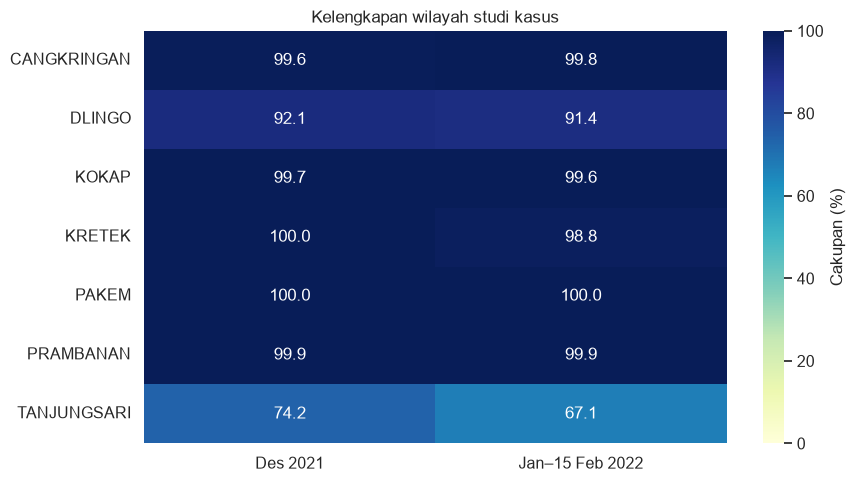

,destination,kapanewon,coverage_min,eligible
0,Kalibiru,KOKAP,0.996377,True
1,Pinus Sari Mangunan,DLINGO,0.913949,True
2,Watu Lumbung,KRETEK,0.988225,True
3,Tebing Breksi,PRAMBANAN,0.998656,True
4,Bhumi Merapi,PAKEM,1.000000,True
5,Lava Tour / Petung,CANGKRINGAN,0.995968,True
6,Pantai Baron,TANJUNGSARI,0.671196,False


In [3]:
assert not raw.duplicated(['kapanewon_code','date','hour']).any()
assert raw.hour.between(0,23).all() and raw.n_maids.ge(5).all()
raw['date']=pd.to_datetime(raw.date)
df=raw[raw.date.between('2021-12-01','2022-02-15')].copy()
df['segment']=np.where(df.date<'2022-01-01',SEGMENTS[0],SEGMENTS[1])
df['weekend']=np.where(df.date.dt.day_of_week>=5,'Akhir pekan','Hari kerja')
area=sites.merge(df.groupby(['kapanewon_code','segment']).size().rename('slots').reset_index(),on='kapanewon_code',how='left')
expected=df.groupby('segment').date.nunique()*24
area['coverage']=area.slots/area.segment.map(expected)
coverage=area.pivot(index='kapanewon',columns='segment',values='coverage').reindex(columns=SEGMENTS)
fig,ax=plt.subplots(figsize=(9,5))
sns.heatmap(coverage*100,annot=True,fmt='.1f',cmap='YlGnBu',vmin=0,vmax=100,ax=ax,cbar_kws={'label':'Cakupan (%)'})
ax.set(title='Kelengkapan wilayah studi kasus',xlabel='',ylabel='');show(fig,'01_coverage')
minimum=area.groupby('kapanewon_code').coverage.min()
eligible=minimum[minimum>=.90].index
selection=sites.assign(coverage_min=sites.kapanewon_code.map(minimum),eligible=sites.kapanewon_code.isin(eligible))
display(selection[['destination','kapanewon','coverage_min','eligible']])

## Mengukur aktivitas siang

Setiap hari harus memiliki seluruh 10 jam dari 08 sampai 17. Ukuran aktivitas adalah **rata-rata hitungan perangkat per jam** dalam jendela tersebut; hitungan tidak dijumlahkan menjadi perangkat unik harian. Hari kerja dan akhir pekan dibandingkan dalam wilayah dan periode sampel yang sama.

Perubahan akhir pekan = `100 × (rerata aktivitas akhir pekan / rerata aktivitas hari kerja − 1)`. Untuk masuk pemeringkatan, suatu wilayah membutuhkan sedikitnya 4 hari akhir pekan dan 10 hari kerja lengkap pada masing-masing periode. Indeks profil harian dari proyek sebelumnya tidak dipakai untuk membandingkan tingkat aktivitas.

In [4]:
window=df[df.kapanewon_code.isin(eligible)&df.hour.between(8,17)]
daily=window.groupby(['kapanewon_code','segment','date','weekend']).n_maids.agg(activity='mean',hours='size').reset_index()
daily=daily[daily.hours==10].merge(sites,on='kapanewon_code',validate='many_to_one')
counts=daily.groupby(['kapanewon_code','segment','weekend']).size().unstack(fill_value=0)
ok=counts[(counts['Akhir pekan']>=4)&(counts['Hari kerja']>=10)].groupby('kapanewon_code').size()
valid=ok[ok==2].index
daily=daily[daily.kapanewon_code.isin(valid)].copy()
means=daily.groupby(['kapanewon','segment','weekend']).activity.mean().unstack()
means['lift_pct']=100*(means['Akhir pekan']/means['Hari kerja']-1)
lift=means.lift_pct.unstack().reindex(columns=SEGMENTS)
order=lift.mean(axis=1).sort_values().index
print('Kasus layak dibandingkan:',len(valid),'dari',len(sites))
display(counts)
selection.to_csv(TABLES/'case_selection.csv',index=False)
daily.to_csv(TABLES/'complete_daytime_presence.csv',index=False)
means.to_csv(TABLES/'weekend_comparison.csv')

Kasus layak dibandingkan: 6 dari 7


weekend                         Akhir pekan  Hari kerja
kapanewon_code segment                                 
34.01.08       Des 2021                   8          23
               Jan–15 Feb 2022           14          31
34.02.03       Des 2021                   8          23
               Jan–15 Feb 2022           14          32
34.02.11       Des 2021                   7          22
               Jan–15 Feb 2022           13          30
34.04.09       Des 2021                   8          23
               Jan–15 Feb 2022           14          32
34.04.16       Des 2021                   8          23
               Jan–15 Feb 2022           14          32
34.04.17       Des 2021                   8          23
               Jan–15 Feb 2022           14          32

## Perbandingan akhir pekan pada dua periode

Nilai positif berarti rata-rata hitungan perangkat per jam siang lebih tinggi pada akhir pekan. Nilai negatif berarti lebih rendah. Keduanya merupakan perbandingan deskriptif, bukan estimasi efek pariwisata.

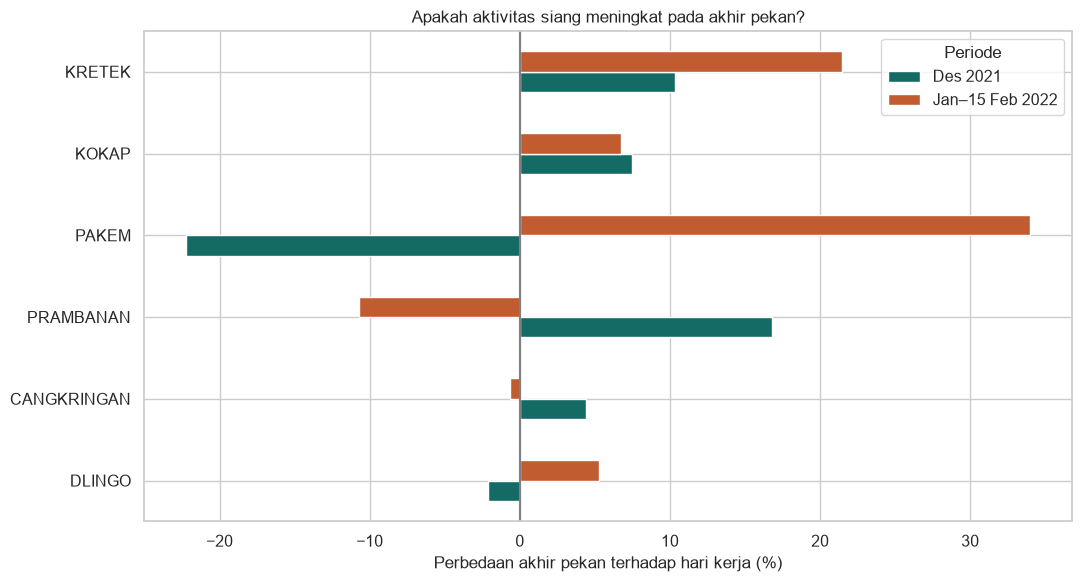

In [5]:
fig,ax=plt.subplots(figsize=(11,6))
lift.loc[order].plot.barh(ax=ax,color=COLORS)
ax.axvline(0,color='gray');ax.set(xlabel='Perbedaan akhir pekan terhadap hari kerja (%)',ylabel='',title='Apakah aktivitas siang meningkat pada akhir pekan?')
ax.legend(title='Periode');show(fig,'02_weekend_lift')

## Besarnya tingkat aktivitas dalam setiap kasus

Panel dipisahkan per wilayah agar skala hitungan yang berbeda tidak menutupi pola. Bandingkan batang dalam panel yang sama; jangan menggabungkan perangkat antarwilayah.

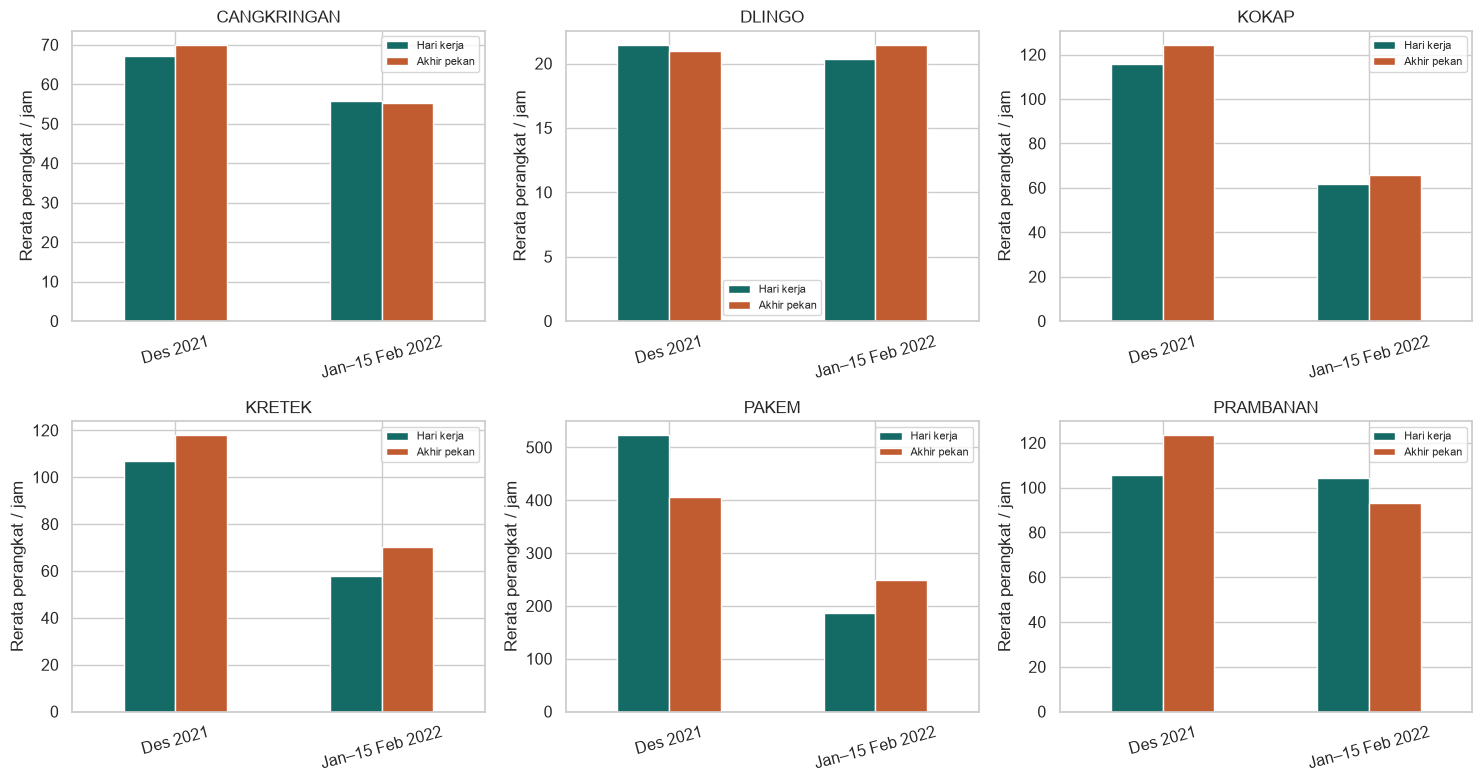

In [6]:
names=lift.index.tolist()
fig,axes=plt.subplots(2,3,figsize=(15,8));axes=np.asarray(axes).ravel()
for ax,name in zip(axes,names):
    means.loc[name][['Hari kerja','Akhir pekan']].plot.bar(ax=ax,color=COLORS,rot=15)
    ax.set(title=name,xlabel='',ylabel='Rerata perangkat / jam');ax.legend(fontsize=8)
for ax in axes[len(names):]:ax.set_visible(False)
show(fig,'03_activity_levels')

## Pola aktivitas menurut jam

Kurva memakai semua jam terbit pada hari siang yang lengkap, kemudian dibagi rerata hari kerja per wilayah dan periode. Indeks 1 berarti tingkat rata-rata hari kerja wilayah tersebut. Bobot tiap wilayah sama; selisih kurva tidak menyatakan jumlah wisatawan.

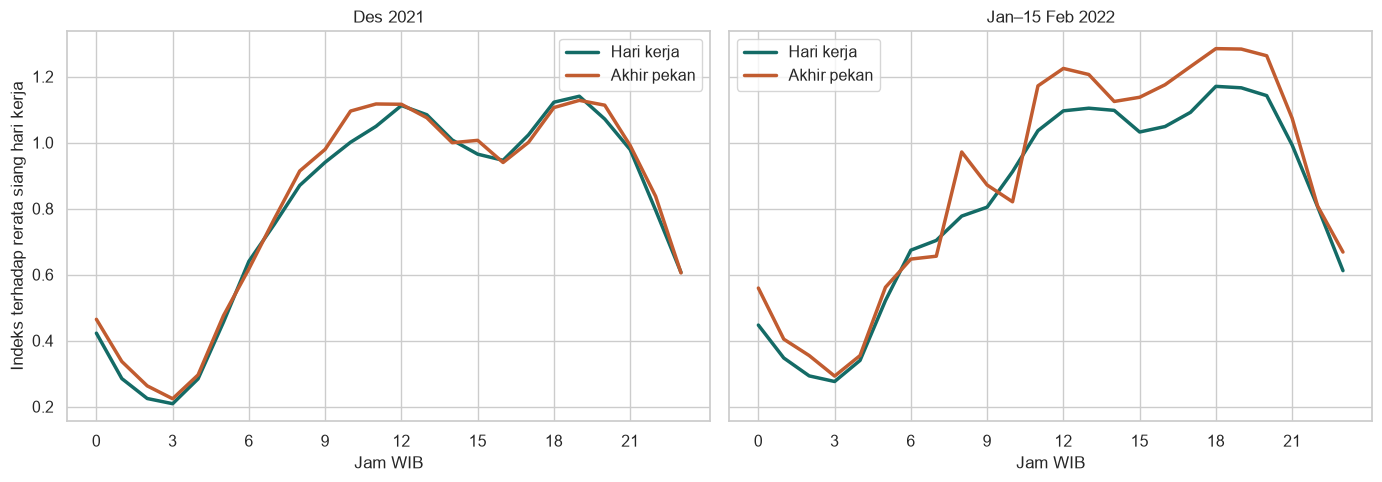

In [7]:
baseline=means['Hari kerja'].rename('baseline').reset_index()
observed=df.merge(daily[['kapanewon_code','date']],on=['kapanewon_code','date'],validate='many_to_one').merge(sites[['kapanewon_code','kapanewon']],on='kapanewon_code',suffixes=('','_site'))
observed=observed.merge(baseline,on=['kapanewon','segment'],validate='many_to_one')
observed['index']=observed.n_maids/observed.baseline
profiles=observed.groupby(['kapanewon','segment','weekend','hour'])['index'].mean().reset_index()
combined=profiles.groupby(['segment','weekend','hour'])['index'].mean().reset_index()
fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,seg in zip(axes,SEGMENTS):
    for group,color in zip(['Hari kerja','Akhir pekan'],COLORS):
        v=combined[(combined.segment==seg)&(combined.weekend==group)]
        ax.plot(v.hour,v['index'],label=group,color=color,lw=2.5)
    ax.set(title=seg,xlabel='Jam WIB',xticks=range(0,24,3));ax.legend()
axes[0].set_ylabel('Indeks terhadap rerata siang hari kerja');show(fig,'04_hourly_profiles')

## Kapan selisihnya muncul?

Heatmap berisi selisih indeks akhir pekan dikurangi hari kerja pada setiap jam. Skala warna dipusatkan pada nol supaya kenaikan dan penurunan terlihat seimbang.

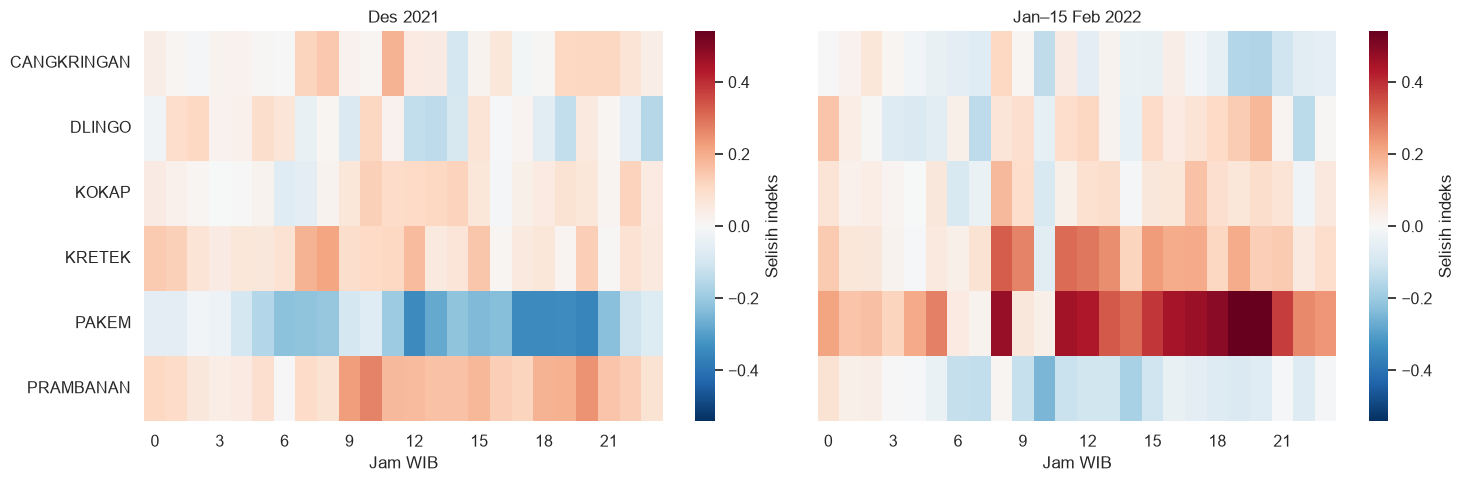

In [8]:
hour_gap=profiles.pivot(index=['segment','kapanewon','hour'],columns='weekend',values='index')
hour_gap['gap']=hour_gap['Akhir pekan']-hour_gap['Hari kerja']
limit=max(.1,abs(hour_gap.gap).max())
fig,axes=plt.subplots(1,2,figsize=(15,5),sharey=True)
for ax,seg in zip(axes,SEGMENTS):
    mat=hour_gap.loc[seg].gap.unstack().reindex(names)
    sns.heatmap(mat,ax=ax,cmap='RdBu_r',center=0,vmin=-limit,vmax=limit,xticklabels=3,cbar_kws={'label':'Selisih indeks'})
    ax.set(title=seg,xlabel='Jam WIB',ylabel='')
show(fig,'05_hourly_gap')

## Pola hari dalam minggu

Aktivitas siang harian dibagi rata-rata hari kerja pada wilayah dan periode yang sama. Ringkasan dihitung per wilayah lebih dulu, kemudian diberi bobot sama. Angka ini menghindari dominasi wilayah dengan hitungan perangkat lebih besar.

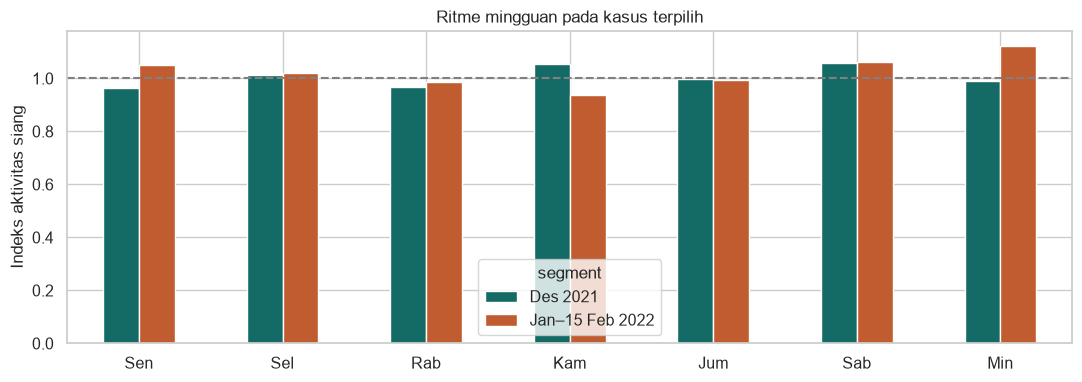

In [9]:
daily=daily.merge(baseline,on=['kapanewon','segment'],validate='many_to_one')
daily['index']=daily.activity/daily.baseline
daily['dow']=daily.date.dt.day_of_week
weekday=daily.groupby(['kapanewon','segment','dow'])['index'].mean().groupby(['segment','dow']).mean().unstack(0)
fig,ax=plt.subplots(figsize=(11,4));weekday.plot.bar(ax=ax,color=COLORS,rot=0)
ax.set(xticklabels=['Sen','Sel','Rab','Kam','Jum','Sab','Min'],xlabel='',ylabel='Indeks aktivitas siang',title='Ritme mingguan pada kasus terpilih');ax.axhline(1,color='gray',ls='--');show(fig,'06_weekday_rhythm')

## Perubahan dari hari ke hari

Panel dipisah pada pergantian sampel. Garis memperlihatkan indeks aktivitas siang dan titik jingga menandai akhir pekan. Puncak tunggal dapat berkaitan dengan kalender libur, pencatatan aplikasi, atau aktivitas lain. Jumlah wilayah yang menyumbang setiap tanggal dapat berbeda bila ada hari tidak lengkap.

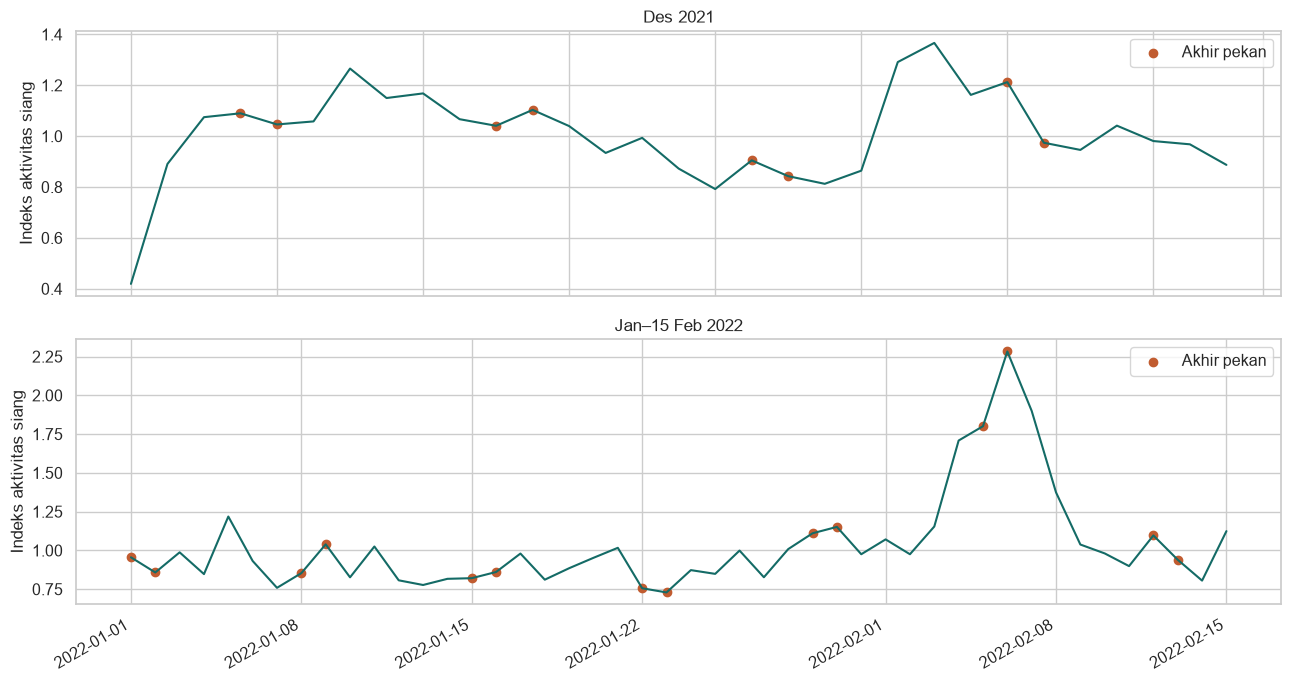

In [10]:
trend=daily.groupby(['segment','date','weekend'])['index'].mean().reset_index()
fig,axes=plt.subplots(2,1,figsize=(13,7))
for ax,seg in zip(axes,SEGMENTS):
    v=trend[trend.segment==seg];w=v[v.weekend=='Akhir pekan']
    ax.plot(v.date,v['index'],color=COLORS[0]);ax.scatter(w.date,w['index'],color=COLORS[1],label='Akhir pekan')
    ax.set(title=seg,ylabel='Indeks aktivitas siang');ax.legend()
fig.autofmt_xdate();show(fig,'07_daily_trend')

## Pemeriksaan tanggal khusus

Sebagai pemeriksaan sensitivitas, perbandingan diulang tanpa 25 Desember 2021, 1 Januari 2022, dan 1 Februari 2022. Ini hanya pemeriksaan tiga tanggal, bukan pengendalian lengkap kalender libur atau pandemi.

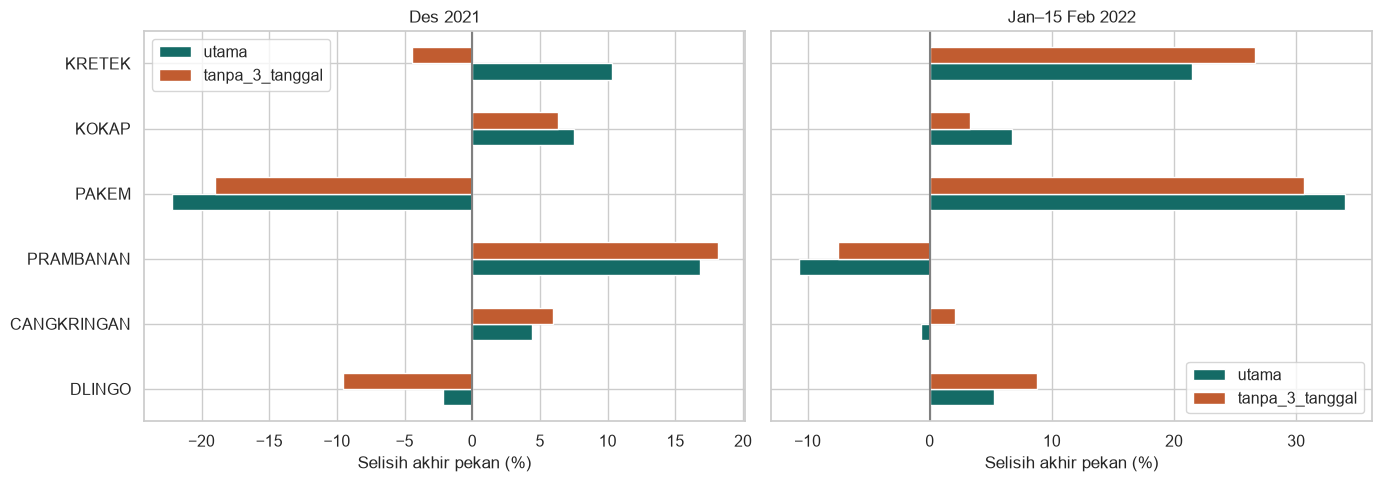

In [11]:
trim=daily[~daily.date.isin(pd.to_datetime(['2021-12-25','2022-01-01','2022-02-01']))]
special=trim.groupby(['kapanewon','segment','weekend']).activity.mean().unstack()
special['lift_pct']=100*(special['Akhir pekan']/special['Hari kerja']-1)
sensitivity=pd.DataFrame({'utama':means.lift_pct,'tanpa_3_tanggal':special.lift_pct})
fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,seg in zip(axes,SEGMENTS):
    sensitivity.xs(seg,level='segment').reindex(order).plot.barh(ax=ax,color=COLORS)
    ax.axvline(0,color='gray');ax.set(title=seg,xlabel='Selisih akhir pekan (%)',ylabel='')
show(fig,'08_special_dates')
sensitivity.to_csv(TABLES/'sensitivity_dates.csv')

## Stabilitas perbedaan antarperiode

Tiap titik mewakili satu wilayah. Kuadran kanan atas berarti perbedaan positif pada dua periode, kiri bawah negatif pada dua periode. Perubahan tanda menandakan hasil tidak konsisten antarperiode.

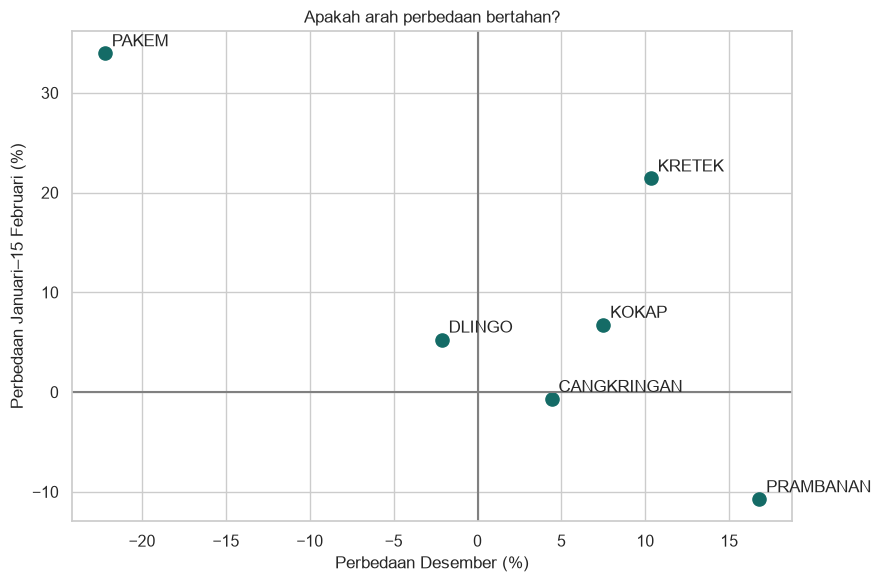

In [12]:
fig,ax=plt.subplots(figsize=(9,6))
ax.scatter(lift[SEGMENTS[0]],lift[SEGMENTS[1]],s=90,color=COLORS[0])
for name,row in lift.iterrows():ax.annotate(name,(row.iloc[0],row.iloc[1]),xytext=(5,5),textcoords='offset points')
ax.axhline(0,color='gray');ax.axvline(0,color='gray')
ax.set(xlabel='Perbedaan Desember (%)',ylabel='Perbedaan Januari–15 Februari (%)',title='Apakah arah perbedaan bertahan?');show(fig,'09_period_stability')

## Sebaran wilayah studi kasus

Peta titik menunjukkan lokasi representatif kapanewon dari [OpenStreetMap](https://www.openstreetmap.org/copyright), diambil melalui Nominatim. Posisi ini merupakan referensi administratif saat pengambilan data, bukan koordinat destinasi atau batas wilayah historis. Warna menunjukkan selisih akhir pekan; titik abu-abu dikeluarkan karena cakupan kurang.

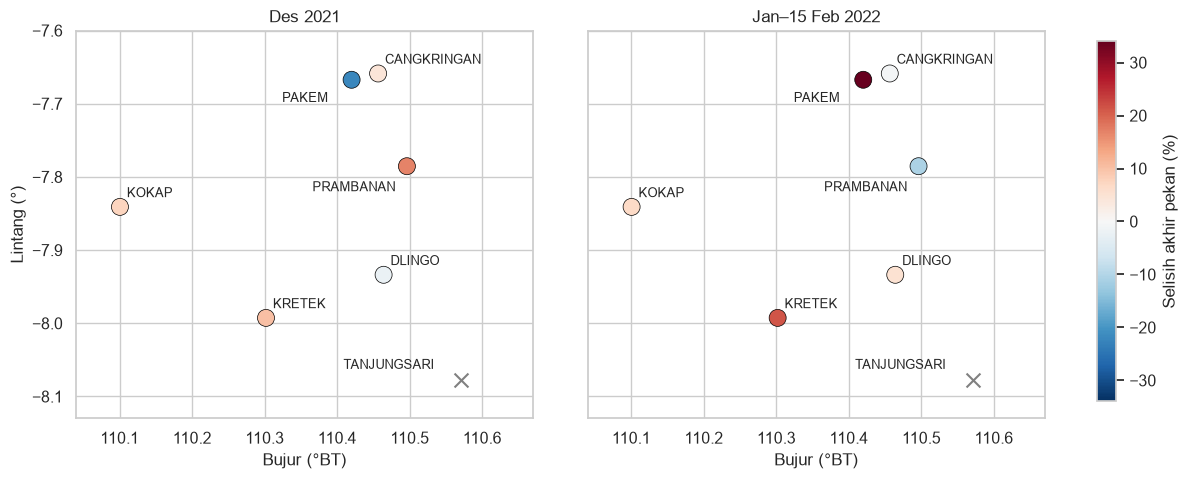

In [13]:
LOCATION_URL='https://docs.google.com/spreadsheets/d/1_gXsB8Mg7vkoK0HiGuug1Ei0TJu75jdrVbL6maZkzm4/export?format=csv&gid=202212'
locations=read_csv(LOCATION_URL,dtype={'kapanewon_code':str})
locations['latitude']=pd.to_numeric(locations.latitude)
locations['longitude']=pd.to_numeric(locations.longitude)
mapped=locations.merge(lift.reset_index(),on='kapanewon',how='left',validate='one_to_one')
from matplotlib.colors import TwoSlopeNorm
limit=max(abs(lift.to_numpy()).max(),1)
fig,axes=plt.subplots(1,2,figsize=(13,6),sharex=True,sharey=True)
for ax,seg in zip(axes,SEGMENTS):
    missing=mapped[mapped[seg].isna()]
    ax.scatter(missing.longitude,missing.latitude,c='gray',marker='x',s=100)
    good=mapped[mapped[seg].notna()]
    points=ax.scatter(good.longitude,good.latitude,c=good[seg],cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),s=150,edgecolors='black',linewidth=.5)
    for _,row in mapped.iterrows():
        offset={'PAKEM':(-50,-16),'TANJUNGSARI':(-85,8),'PRAMBANAN':(-68,-18)}.get(row.kapanewon,(5,7))
        ax.annotate(row.kapanewon,(row.longitude,row.latitude),xytext=offset,textcoords='offset points',fontsize=9)
    ax.set(title=seg,xlabel='Bujur (°BT)',xlim=(110.04,110.67),ylim=(-8.13,-7.6))
    ax.set_aspect(1/np.cos(np.deg2rad(-7.8)))
axes[0].set_ylabel('Lintang (°)')
fig.subplots_adjust(right=.87,wspace=.12)
cax=fig.add_axes([.91,.2,.015,.6])
fig.colorbar(points,cax=cax,label='Selisih akhir pekan (%)')
fig.savefig(FIG/'10_case_map.png',dpi=160,bbox_inches='tight')
fig.savefig(FIG/'10_case_map.pdf',bbox_inches='tight')
plt.show();plt.close(fig)

## Kesimpulan dari data

Jawaban dibatasi pada wilayah studi kasus yang memenuhi syarat. Kenaikan presence tidak membuktikan kenaikan kunjungan wisata atau efek keberadaan destinasi. Sumber lokasi membuktikan keberadaan destinasi pada wilayah; data ini tidak mengidentifikasi tujuan tiap perangkat.

In [14]:
positive=lift[(lift>0).all(axis=1)].index.tolist()
negative=lift[(lift<0).all(axis=1)].index.tolist()
mixed=lift[~((lift>0).all(axis=1)|(lift<0).all(axis=1))].index.tolist()
print('Lebih tinggi pada akhir pekan di dua periode:',', '.join(positive) or 'Tidak ada')
print('Lebih rendah di dua periode:',', '.join(negative) or 'Tidak ada')
print('Arah berbeda antarperiode:',', '.join(mixed) or 'Tidak ada')
display(lift.round(2))
findings={'question':'Apakah kawasan wisata terpilih lebih aktif saat akhir pekan?','documented_cases':len(sites),'eligible_cases':len(valid),'positive_both':positive,'negative_both':negative,'mixed':mixed,'lift_by_area':lift.reset_index().to_dict(orient='records')}
(ROOT/'findings.json').write_text(json.dumps(findings,indent=2))
assert len(means)==2*len(valid)
assert daily.hours.eq(10).all()
assert daily.activity.ge(5).all()
assert len(raw)==230418
print('Pemeriksaan data dan perhitungan lulus.')
print('Gambar PNG/PDF:',FIG)

Lebih tinggi pada akhir pekan di dua periode: KOKAP, KRETEK
Lebih rendah di dua periode: Tidak ada
Arah berbeda antarperiode: CANGKRINGAN, DLINGO, PAKEM, PRAMBANAN


segment,Des 2021,Jan–15 Feb 2022
kapanewon,,
CANGKRINGAN,4.41,-0.68
DLINGO,-2.14,5.27
KOKAP,7.49,6.76
KRETEK,10.33,21.43
PAKEM,-22.22,33.98
PRAMBANAN,16.79,-10.73


Pemeriksaan data dan perhitungan lulus.
Gambar PNG/PDF: /var/folders/v2/j8v2bgkx5d54gyfkbcjqhxv00000gn/T/jogja-wisata-ciht2as1/figures


## Menyimpan hasil

Gambar tampil langsung di bawah setiap bagian. Klik kanan gambar untuk menyimpannya atau ambil PNG/PDF dari panel Files. Tidak ada unduhan ZIP otomatis. Simpan notebook beserta output melalui File → Save a copy in Drive.